In [1]:
import sys
from pathlib import Path
_ROOT = Path.cwd().parent.resolve()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from    pathlib         import  Path
from    tqdm.notebook   import  tqdm

import  torch
from    torch.utils.data    import  TensorDataset, DataLoader
import  matplotlib.pyplot   as  plt
from    math                import  log2

from    core.utils    import  velocity_grid, relative_error
from    core.numerical.math   import  area_of_unit_sphere
from    core.numerical.solver     import  LAMBDA, one_step_RK4_classic, FastSM_Boltzmann_VHS
from    core.numerical.distribution   import  maxwellian_homogeneous, compute_moments_homogeneous
from    core.neural.collision_op  import  PRFNO


DEVICE = torch.device('cuda:0')
base_path = _ROOT
assert base_path.exists()

In [2]:
DIMENSION   = 2
N_LAYERS    = 4
MAX_FREQ    = 8
SEED        = 0
MODEL_TYPE  = "prfno"

DELTA_T     = 0.1
MAX_T       = 5.0
RES_T       = int(1.05+(MAX_T/DELTA_T))
LTE_T       = 20.0
RES_T_LTE   = int(1.05+(LTE_T/DELTA_T))
RESOLUTION  = 2**6
MAX_V       = 3.0/LAMBDA

COL_COEFF   = 1/area_of_unit_sphere(DIMENSION)
EXP_SPEED   = torch.arange(21)*0.05

path = base_path/f"pretrained"
model_and_history = torch.load(path/f"{MODEL_TYPE.upper()}_{DIMENSION}D"/"model_and_history.pth", weights_only=False, map_location='cpu')
INVERSE_COEFF = float(model_and_history['inverse_coeff'])
print(model_and_history.keys())

dict_keys(['args', 'state_dict', 'train_history', 'inverse_coeff'])


torch.Size([21, 64, 64, 1])


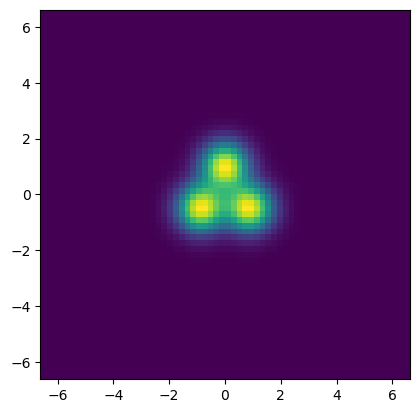

In [3]:
# Generate data
mu1 = torch.ones((1, 1))
mu2 = torch.ones((1, 1))
mu3 = torch.ones((1, 1))
c1 = torch.tensor([[1.0, 0.0]])
c2 = torch.tensor([[-0.5, +0.5*(3**0.5)]])
c3 = torch.tensor([[-0.5, -0.5*(3**0.5)]])
rho1 = torch.ones((1, 1)) / 3
rho2 = torch.ones((1, 1)) / 3
rho3 = torch.ones((1, 1)) / 3
v_grid = velocity_grid(DIMENSION, RESOLUTION, MAX_V)
f_init = (
    maxwellian_homogeneous(v_grid, mu1, c1, rho1) + \
    maxwellian_homogeneous(v_grid, mu2, c2, rho2) + \
    maxwellian_homogeneous(v_grid, mu3, c3, rho3)
) / 3
for _ in range(DIMENSION):  f_init.squeeze_(1)

param = torch.linspace(0, 1, 21, device=DEVICE)[:, None]
f_init = f_init.repeat_interleave(len(param), dim=0)

print(f_init.shape)
plt.imshow(f_init[0].squeeze(), origin='lower', extent=[-MAX_V, MAX_V]*2)
plt.show()

In [4]:
prfno = PRFNO(**model_and_history['args']).to(DEVICE)
prfno.load_state_dict(model_and_history['state_dict'])
prfno.eval()
v_grid = velocity_grid(DIMENSION, RESOLUTION, MAX_V, device=DEVICE)

In [ ]:
pred_list = []
with torch.inference_mode():
    f_pred   = f_init.to(DEVICE)
    params   = param.to(DEVICE)
    pred_list_batch = [f_pred.clone().cpu()]
    fwd = lambda t, f: (COL_COEFF/INVERSE_COEFF)*prfno.forward(f, v_grid, params)
    for _ in range(RES_T-1):
        f_pred = one_step_RK4_classic(0.0, f_pred, DELTA_T, fwd)
        pred_list_batch.append(f_pred.clone().cpu())
    pred_list_batch = torch.stack(pred_list_batch, dim=1)
    pred_list.append(pred_list_batch)
pred_list = torch.cat(pred_list, dim=0)

In [6]:
target_list = []
with torch.inference_mode():
    for p in param.flatten():
        f0 = f_init[[0]].to(DEVICE)
        for _ in range(DIMENSION):  f0.unsqueeze_(1)
        fsm = FastSM_Boltzmann_VHS(DIMENSION, RESOLUTION, MAX_V, vhs_coeff=COL_COEFF, vhs_alpha=p.item(), device=DEVICE)
        target_list_batch = fsm.solve(0.0, MAX_T, DELTA_T, f0, one_step_RK4_classic)
        for _ in range(DIMENSION):  target_list_batch.squeeze_(2)
        target_list.append(target_list_batch.cpu())
target_list = torch.cat(target_list, dim=0)

  0%|          | 0/50 [00:00<?, ?it/s]

100%|██████████| 50/50 [00:00<00:00, 165.97it/s]


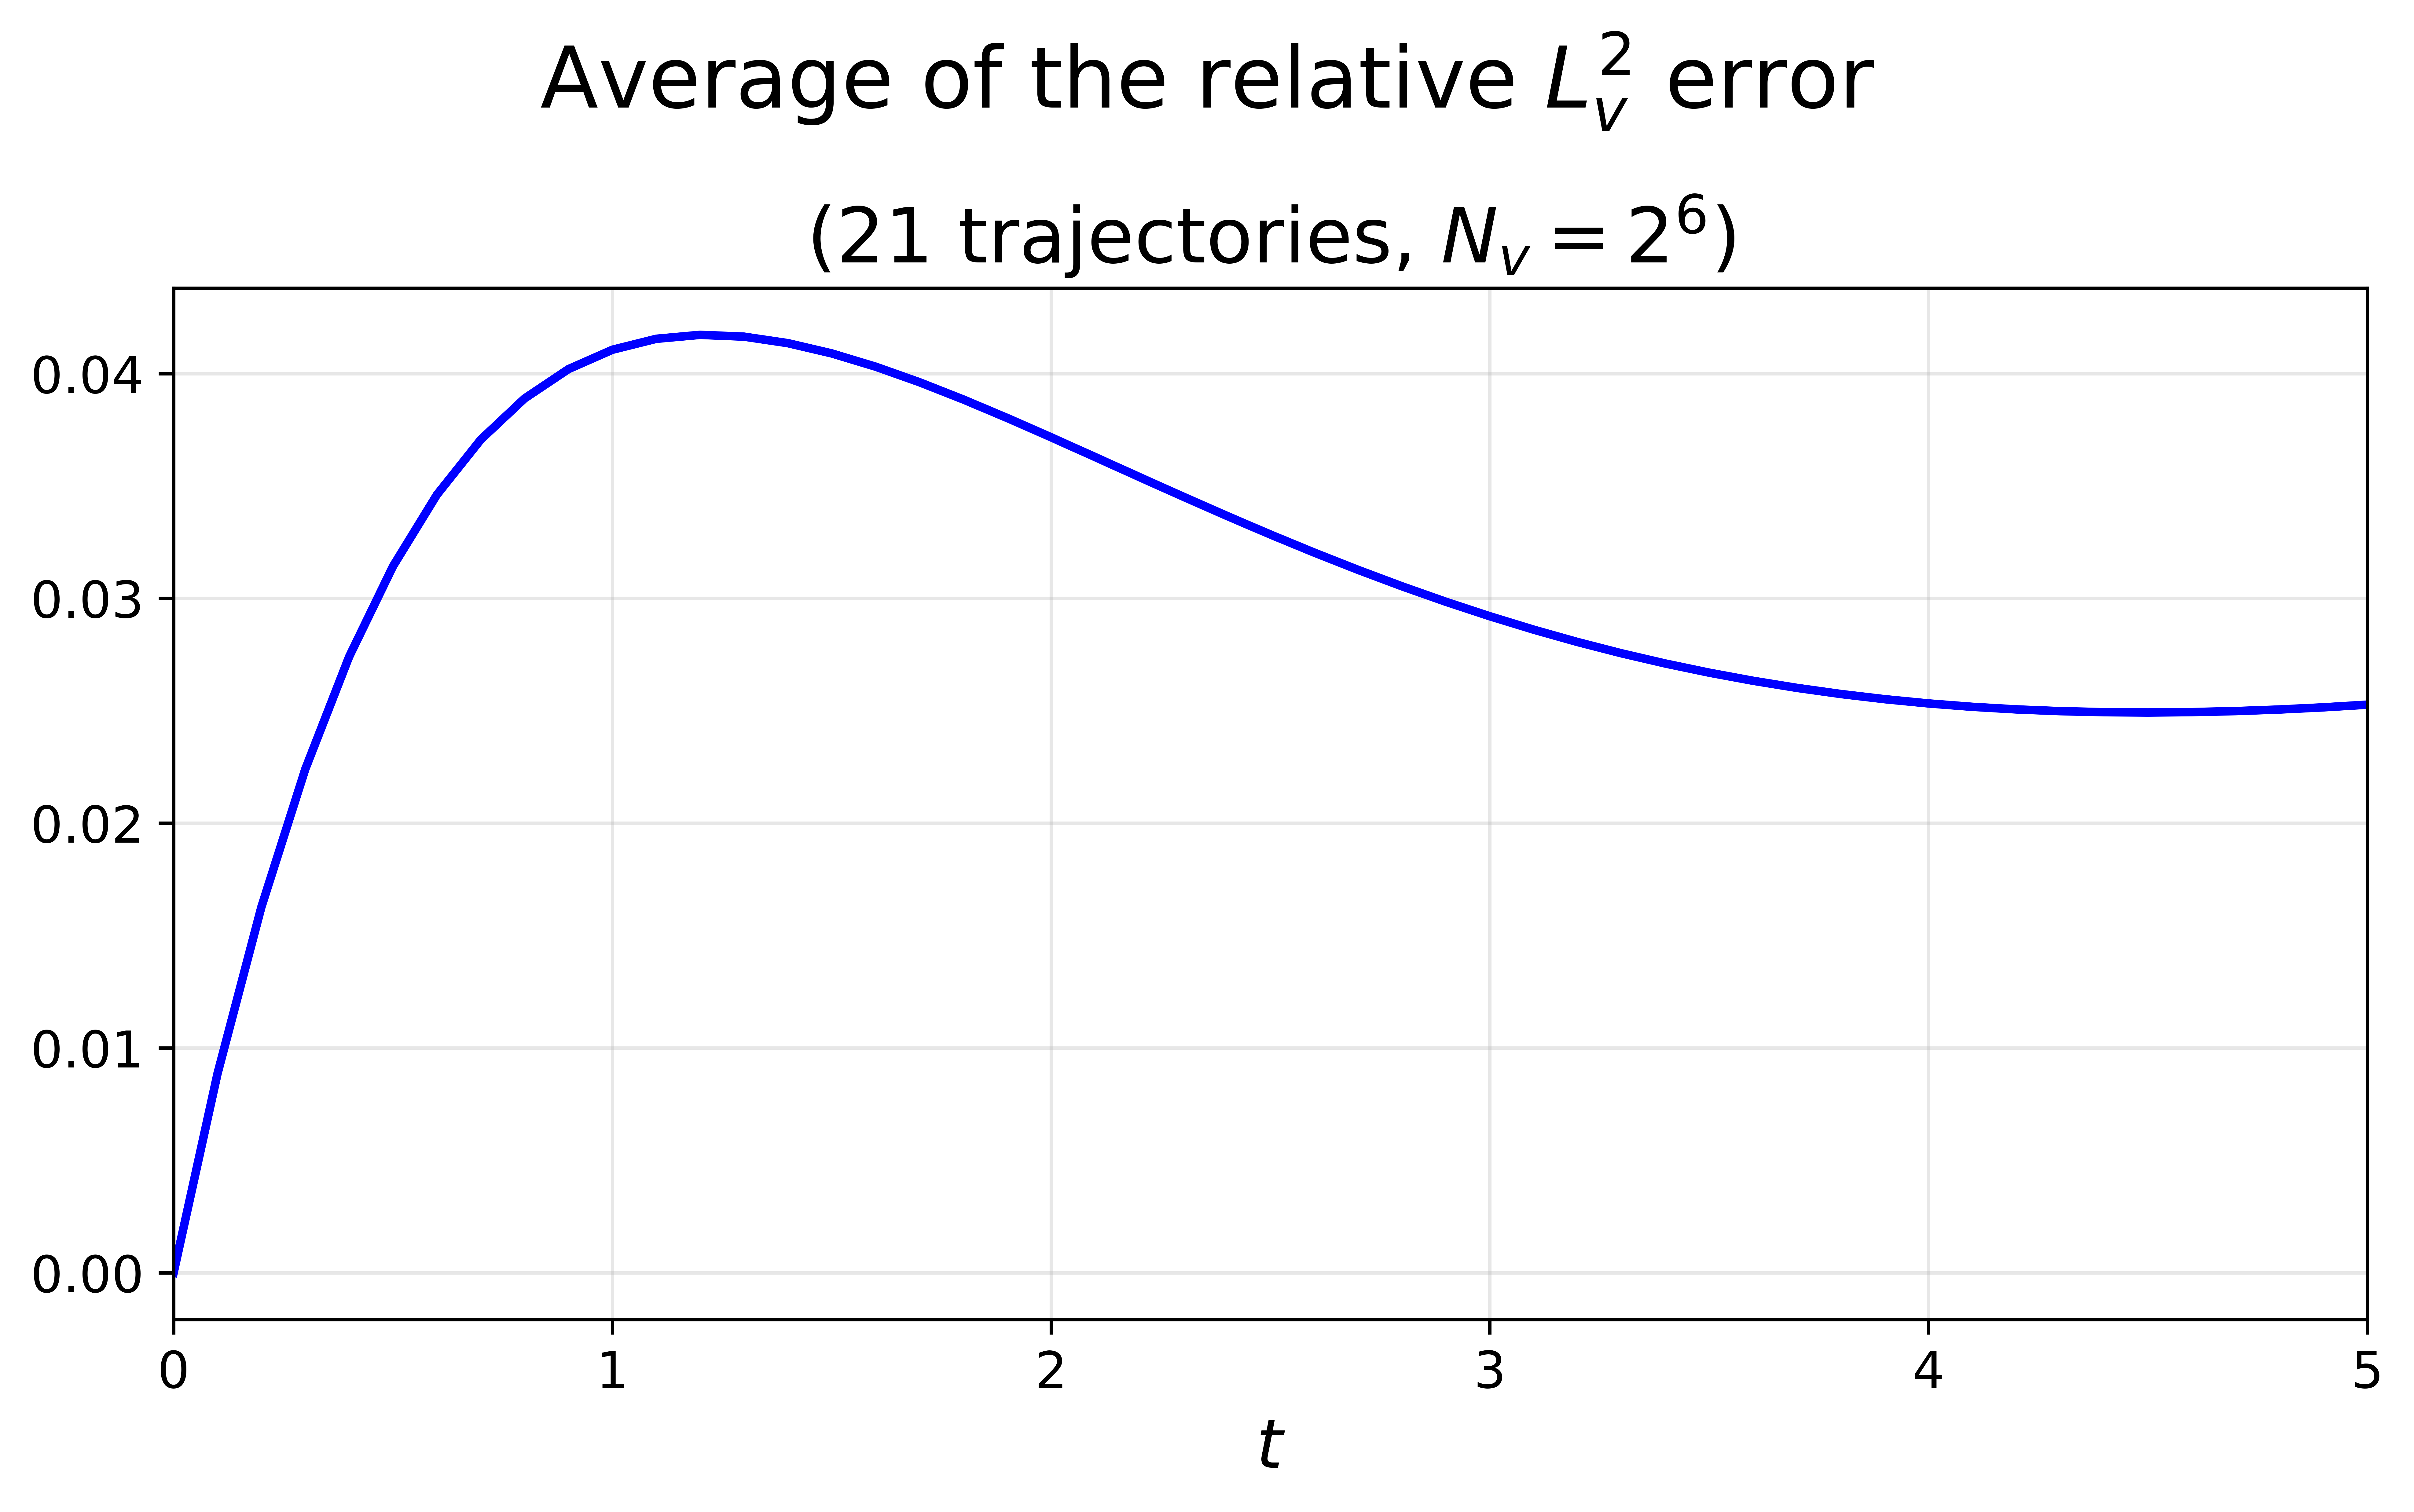

In [13]:
assert pred_list.shape==target_list.shape

error = relative_error(pred_list, target_list, p=2, dim=tuple(range(2, 2+DIMENSION+1)))

arr_t = torch.arange(RES_T)*DELTA_T
error_mean = error.mean(dim=0)
error_std  = error.std(dim=0)

plt.figure(figsize=(8, 5), dpi=1000)
plt.suptitle(f"Average of the relative $L^2_{{v}}$ error", fontsize=20)
plt.title(rf"({f_init.size(0)} trajectories, $N_v=2^{ '{'+str(int(log2(RESOLUTION)))+'}' }$)", fontsize=18)
plt.plot(arr_t, error_mean.cpu(), c='blue', linewidth=2)

plt.xlabel("$t$", fontsize=16)
plt.xlim(arr_t.min(), arr_t.max())
# plt.ylim(0.0, 1e-2)
plt.tick_params(labelsize=12)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"average_error__{DIMENSION}D__res{RESOLUTION:03d}.pdf", dpi=1000)
plt.show()
plt.close()

End of file